# Mandatory assignment 3

**GitHub repository:** https://github.com/LucaLonngren/TECH2-H26-assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [1]:

# Part 1 -- Data preparation

import pandas as pd

# 1. Load the data and analyze columns
data = pd.read_csv("SCF_10pct.csv")

print("The columns in the dataset are:")
print(data.columns)

print("Information about the dataset:")
data.info(show_counts=True)

# 2. Remove observations missing values
print()
print("Number of missing values in each variable:")
print(data.isnull().sum())

before = len(data)
data = data.dropna(subset=["id"])
after = len(data)
print("Rows deleted because id was missing:", before - after)

before = len(data)
data = data.dropna(subset=["year"])
after = len(data)
print("Rows deleted because year was missing:", before - after)

before = len(data)
data = data.dropna(subset=["age"])
after = len(data)
print("Rows deleted because age was missing:", before - after)

before = len(data)
data = data.dropna(subset=["educ"])
after = len(data)
print("Rows deleted because educ was missing:", before - after)

before = len(data)
data = data.dropna(subset=["stocks"])
after = len(data)
print("Rows deleted because stocks was missing:", before - after)

before = len(data)
data = data.dropna(subset=["equity"])
after = len(data)
print("Rows deleted because equity was missing:", before - after)

print("Number of rows after deleting missing values:", len(data))

# 3. Keep observations between 25 and 89

before = len(data)

data = data[data["age"] >= 25]
data = data[data["age"] <= 89]

after = len(data)

print("Rows deleted by the age restriction:", before - after)
print("Number of rows remaining:", len(data))

# 4. Creation of the indicator columns

data["direct"] = 0
data.loc[data["stocks"] > 0, "direct"] = 1

data["overall"] = 0
data.loc[data["equity"] > 0, "overall"] = 1

print("First five rows of the final dataset:")
display(data.head())

The columns in the dataset are:
Index(['id', 'year', 'age', 'educ', 'stocks', 'equity'], dtype='str')
Information about the dataset:
<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB

Number of missing values in each variable:
id         0
year       0
age        0
educ      16
stocks    18
equity    16
dtype: int64
Rows deleted because id was missing: 0
Rows deleted because year was missing: 0
Rows deleted because age was missing: 0
Rows deleted because educ was missing: 16
Rows deleted because stocks was missing: 18
Rows deleted because equity was missing: 16
Number of rows after deleting missing v

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [2]:

# Part 2 -- Participation rates


# 1. Write a function to calculate the participation rate

def participation_rate(indicator):

    count = 0

    for value in indicator:
        if value == 1:
            count = count + 1

    rate = count / len(indicator) * 100

    return rate


# 2. Applying function to final sample

direct_rate = participation_rate(data["direct"])
overall_rate = participation_rate(data["overall"])

print("Direct participation rate:", round(direct_rate, 2), "%")
print("Overall participation rate:", round(overall_rate, 2), "%")


# 3. Using pandas to calculate the participation rates

direct_rate_pandas = data["direct"].mean() * 100
overall_rate_pandas = data["overall"].mean() * 100

print("Direct participation rate using pandas:",
      round(direct_rate_pandas, 2), "%")

print("Overall participation rate using pandas:",
      round(overall_rate_pandas, 2), "%")


Direct participation rate: 16.96 %
Overall participation rate: 49.41 %
Direct participation rate using pandas: 16.96 %
Overall participation rate using pandas: 49.41 %


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

Participation rates by education:

Education category: 1
Direct participation: 4.4 %
Overall participation: 17.3 %

Education category: 2
Direct participation: 11.4 %
Overall participation: 39.9 %

Education category: 3
Direct participation: 13.5 %
Overall participation: 48.3 %

Education category: 4
Direct participation: 30.5 %
Overall participation: 73.5 %



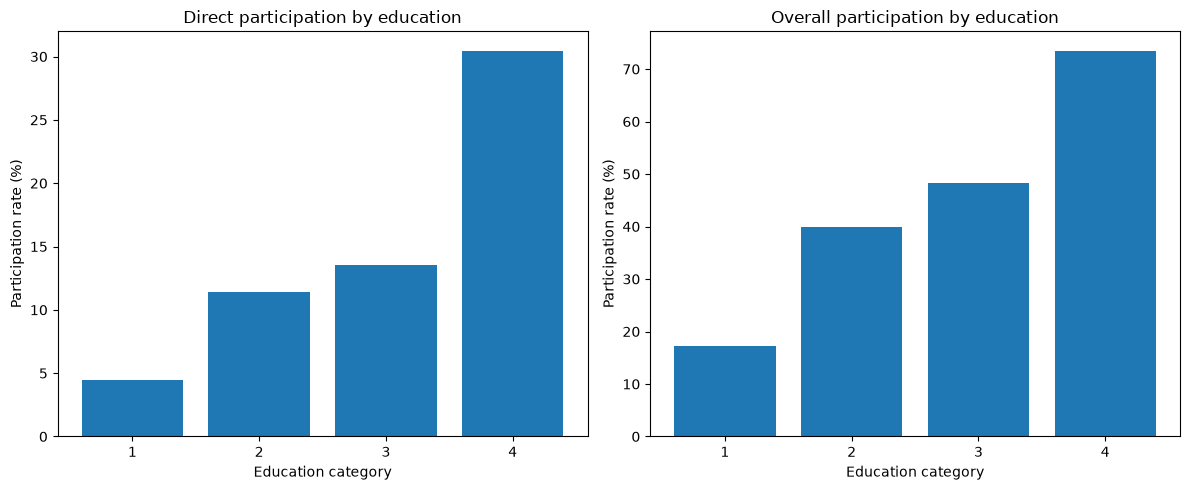

Participation rates increase with education. People with a bachelor's degree or higher invest the most, while those without a high school diploma invest the least. Overall participation is higher than direct participation in every education level.


In [3]:
# Part 3: Participation by education

import matplotlib.pyplot as plt


# 1. Calculate participation rates for each education category

education_levels = [1, 2, 3, 4]

direct_rates = []
overall_rates = []

for education in education_levels:

    # Select households with this education level
    education_data = data[data["educ"] == education]

    # Calculate direct participation rate
    direct_rate = education_data["direct"].mean() * 100

    # Calculate overall participation rate
    overall_rate = education_data["overall"].mean() * 100

    # Save the results
    direct_rates.append(direct_rate)
    overall_rates.append(overall_rate)


# 2. Display the results

print("Participation rates by education:")
print()

for i in range(len(education_levels)):

    print("Education category:", education_levels[i])
    print("Direct participation:", round(direct_rates[i], 1), "%")
    print("Overall participation:", round(overall_rates[i], 1), "%")
    print()


# 3. Create two bar charts

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(education_levels, direct_rates)
axes[0].set_title("Direct participation by education")
axes[0].set_xlabel("Education category")
axes[0].set_ylabel("Participation rate (%)")
axes[0].set_xticks(education_levels)

axes[1].bar(education_levels, overall_rates)
axes[1].set_title("Overall participation by education")
axes[1].set_xlabel("Education category")
axes[1].set_ylabel("Participation rate (%)")
axes[1].set_xticks(education_levels)

plt.tight_layout()
plt.show()

print("Participation rates increase with education. People with a bachelor's degree or higher invest the most, while those without a high school diploma invest the least. Overall participation is higher than direct participation in every education level.")

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

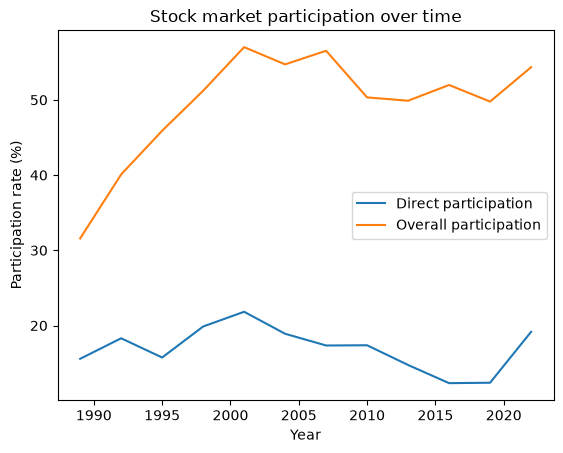

Change in direct participation: 3.6 percent
Change in overall participation: 22.8 percent
Participation rates in general increased over time, although they fluctuated between years. From 1989 to 2022, direct participation increased by 3.6 percent, while overall participation increased by 22.8 percent.


In [4]:

# Part 4 -- Participation over time

# 1. Calculate participation rates for each year

years = sorted(data["year"].unique())

direct_rates = []
overall_rates = []

for year in years:
    year_data = data[data["year"] == year]

    direct_rate = year_data["direct"].mean() * 100
    overall_rate = year_data["overall"].mean() * 100

    direct_rates.append(direct_rate)
    overall_rates.append(overall_rate)


# 2. Create a line chart

plt.plot(years, direct_rates, label="Direct participation")
plt.plot(years, overall_rates, label="Overall participation")

plt.xlabel("Year")
plt.ylabel("Participation rate (%)")
plt.title("Stock market participation over time")
plt.legend()
plt.show()


# 3. Calculate the change from 1989 to 2022

direct_change = direct_rates[-1] - direct_rates[0]
overall_change = overall_rates[-1] - overall_rates[0]

print("Change in direct participation:",
      round(direct_change, 1), "percent")

print("Change in overall participation:",
      round(overall_change, 1), "percent")

print("Participation rates in general increased over time, although they fluctuated between years. From 1989 to 2022, direct participation increased by 3.6 percent, while overall participation increased by 22.8 percent.")


***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used AI when I got stuck and unsure on how to proceed. It helped me understand the steps I needed to take and provided explanations when my Python coding knowledge was not enough to continue independently. I used these explanations to help me complete the assignment and improve my understanding of the code.